In [1]:
# ===========================================
# Libraries
# ===========================================

import numpy as np
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

In [2]:
# ===========================================
# Load chains
# ===========================================

path_base = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MG-based-models/Hu-Sawicki/CC_SNe_BAO/flat_samples_HS_n1_cc_sne_bao.npy"
path_frb  = "/home/brunowesley/projetos/MCMC-cosmo/Codes/MG-based-models/Hu-Sawicki/CC_SNe_BAO_FRB/flat_samples_HS_n1_cc_sne_bao_frb.npy"

samples_base = np.load(path_base)
samples_frb  = np.load(path_frb)

# ===========================================
# Extract parameters (H0: index 0, Ob: index 2)
# ===========================================

H0_base, Ob_base = samples_base[:, 0], samples_base[:, 2]
H0_frb,  Ob_frb  = samples_frb[:, 0],  samples_frb[:, 2]

In [3]:
# ===========================================
# Sanity check: medians must match the main constraints table
# ===========================================
# Guards against a wrong column index for H0/Ob, which would silently
# corrupt the derived combination below.

EXPECTED = {
    "H0_base": 69.69, "Ob_base": 0.0502,
    "H0_frb":  70.32, "Ob_frb":  0.0514,
}
TOL_H0, TOL_OB = 0.5, 0.002

def _check(name, value, expected, tol):
    ok = abs(value - expected) <= tol
    print(f"  [{'OK ' if ok else '!! '}] median {name:8s} = {value:8.4f}   (table: {expected}, |diff|<={tol})")
    return ok

print("Sanity check on column indexing:")
all_ok = all([
    _check("H0_base", np.median(H0_base), EXPECTED["H0_base"], TOL_H0),
    _check("Ob_base", np.median(Ob_base), EXPECTED["Ob_base"], TOL_OB),
    _check("H0_frb",  np.median(H0_frb),  EXPECTED["H0_frb"],  TOL_H0),
    _check("Ob_frb",  np.median(Ob_frb),  EXPECTED["Ob_frb"],  TOL_OB),
])
if not all_ok:
    raise ValueError("Median(s) do not match the table -- check column indices.")
print("All medians consistent with the main table.")

Sanity check on column indexing:
  [OK ] median H0_base  =  69.6868   (table: 69.69, |diff|<=0.5)
  [OK ] median Ob_base  =   0.0502   (table: 0.0502, |diff|<=0.002)
  [OK ] median H0_frb   =  70.3237   (table: 70.32, |diff|<=0.5)
  [OK ] median Ob_frb   =   0.0514   (table: 0.0514, |diff|<=0.002)
All medians consistent with the main table.


In [4]:
# ===========================================
# Helper: marginalized statistics
# ===========================================

def print_stats(x, title):

    median  = np.percentile(x, 50)
    lo68, hi68 = np.percentile(x, [16, 84])
    lo95, hi95 = np.percentile(x, [2.5, 97.5])

    ep68, em68 = hi68 - median, median - lo68
    ep95, em95 = hi95 - median, median - lo95

    print(f"\n{title}:")
    print(f"    {median:.3f} +{ep68:.3f} -{em68:.3f}  (68% CL)")
    print(f"    {median:.3f} +{ep95:.3f} -{em95:.3f}  (95% CL)")

In [5]:
# ===========================================
# Derived parameter: Ob * H0 * fd
# ===========================================
# Combination directly constrained by the Macquart relation, including
# the diffuse baryon fraction fd = 0.83 adopted in this work (Sec. 3).
# Only defined for the Baseline + FRB dataset: fd only enters through
# the FRB likelihood, so the combination is not meaningful for the
# Baseline (CC + SNe + BAO) dataset alone.

fd = 0.83

ObH0fd_frb = Ob_frb * H0_frb * fd

print("\n" + "="*60)
print("                  HS | Ob*H0*fd [km/s/Mpc]                  ")
print("="*60)

print_stats(ObH0fd_frb, "Baseline + FRB (CC + SNe + BAO + FRB)")

print("\n" + "="*60)


                  HS | Ob*H0*fd [km/s/Mpc]                  

Baseline + FRB (CC + SNe + BAO + FRB):
    2.999 +0.135 -0.136  (68% CL)
    2.999 +0.264 -0.268  (95% CL)



Removed no burn in


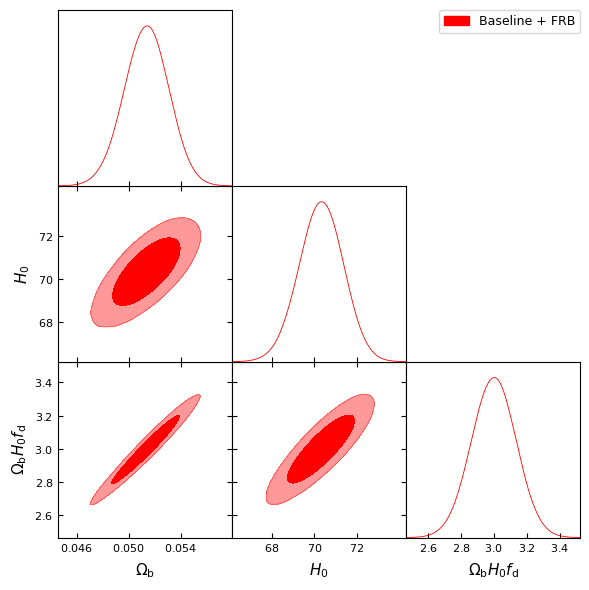

In [6]:
# ===========================================
# Corner plot: (Ob, H0, Ob*H0*fd) triangle
# ===========================================
# Baseline + FRB dataset only (see previous cell).

gd_frb = MCSamples(samples=np.column_stack([Ob_frb, H0_frb, ObH0fd_frb]),
                    names=["Ob", "H0", "ObH0fd"],
                    labels=[r"\Omega_{\rm b}", r"H_0", r"\Omega_{\rm b} H_0 f_{\rm d}"])

gd_frb.updateSettings({"smooth_scale_1D": 0.25, "smooth_scale_2D": 0.3,
                       "fine_bins": 1024, "fine_bins_2D": 1024})

g = plots.get_subplot_plotter()
g.triangle_plot(
    [gd_frb],
    filled=True,
    legend_labels=["Baseline + FRB"],
    contour_colors=["red"],
    title_limit=0,
)

plt.savefig("Corner_HS_n1_ObH0fd.png", dpi=300, bbox_inches="tight")
plt.savefig("Corner_HS_n1_ObH0fd.pdf", dpi=300, bbox_inches="tight")
plt.show()